<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-11/lab-068-interacting-qubits-gates.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 068. Interactions and two-qubit gates

A quantum computer needs many qubits that can be addressed one at a time and made to interact in pairs. A single atom driven by a laser gives one qubit and its rotations. Entanglement needs an interaction between two qubits, and every platform obtains it from a different piece of physics. Neutral atoms interact strongly when both are excited to large Rydberg orbitals. Trapped ions push each other through their Coulomb repulsion and share their vibrations. Superconducting circuits are wired together with capacitors and resonators, and electron spins in neighbouring quantum dots feel the exchange interaction.

All of these mechanisms have the same mathematical form. Written with Pauli operators, a physical interaction between two qubits becomes a sum of Pauli strings, such as $\hat Z\otimes\hat Z$, $\hat X\otimes\hat X$ or $\hat X\otimes\hat X+\hat Y\otimes\hat Y$. Switched on for a chosen time, it produces the evolution operator $e^{-it\hat{\mathcal H}}$, which is a two-qubit gate. At interaction times for which this gate entangles, such as the controlled-Z gate or $\hat R_{xx}(\pi/2)$, it builds every quantum circuit together with single-qubit rotations.

We express the physical couplings as Pauli operators and use their time evolution to construct two-qubit gates. The Rydberg and trapped-ion simulations show how the physical dynamics determine the gate and its error. SWAP gates then apply an operation between distant qubits of a chain. Sections 1 to 6 form the core route, and Sections 7 and 8 can be completed at home. Assertions in the code check the derived identities and the numerical comparisons with the two-level and gate predictions.

The ground state is $|g\rangle=|0\rangle=|{\uparrow}\rangle$, operators carry hats, qubit 0 is the leftmost factor of every Kronecker product, and $\hbar=1$.

In [1]:
# double precision, plotting style, output folders and basic operators
import os, json, time
from functools import reduce
import numpy as np
import scipy.sparse as sp
from scipy.linalg import expm
from scipy.optimize import minimize
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
os.makedirs("classroom_results", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 10, "figure.dpi": 110})
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42})   # TrueType fonts embed cleanly in LaTeX
started = time.perf_counter()
NUMBERS = {}                                                    # numbers exported as LaTeX macros
TOL = 1e-10

def sci(x, digits=1):
    # LaTeX scientific notation for the exported macros, e.g. 1.3\times10^{-3}
    e = int(np.floor(np.log10(abs(x)))); m = x / 10 ** e
    return f"{m:.{digits}f}\\times10^{{{e}}}"

def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = (X + Z) / np.sqrt(2)                                        # Hadamard gate

def kron(*ms):
    return reduce(np.kron, ms)

def ket(bits):
    v = np.zeros(2 ** len(bits), dtype=complex); v[int(bits, 2)] = 1
    return v

def op_on_qubits(ops, N):
    # sparse Kronecker product over N qubits: ops[q] on qubit q (a dict), the identity elsewhere, qubit 0 leftmost
    factors = [sp.csr_matrix(ops[q]) if q in ops else sp.identity(2, dtype=complex, format="csr") for q in range(N)]
    return reduce(lambda A, B: sp.kron(A, B, format="csr"), factors)

def same_up_to_phase(A, B):
    i = np.unravel_index(np.argmax(abs(B)), B.shape)
    phase = A[i] / B[i]
    return abs(abs(phase) - 1) < 1e-9 and np.allclose(A, phase * B, atol=1e-9)

## 1. A register of addressable qubits

A register is a set of $N$ two-level systems. Examples are atoms held in an array of optical tweezers, tightly focused laser beams that each hold one atom, ions in a linear trap and superconducting circuits on a chip. Each qubit $q$ can be driven on its own. A drive with Rabi frequency $\Omega_q$ and detuning $\Delta_q$ contributes the one-qubit Hamiltonian $\frac{\Omega_q}2\hat X_q+\frac{\Delta_q}2\hat Z_q$, where $\hat X_q$ and $\hat Z_q$ act on qubit $q$ and as the identity on all other qubits. Pairs of qubits that are close enough, or wired together, interact, and these pairs form the edges of the connectivity graph of the device. With an Ising coupling of strength $J_{qq'}$ on each edge, the device Hamiltonian reads
$$\hat{\mathcal H}_{\rm dev}=\sum_{q=0}^{N-1}\Big(\frac{\Omega_q}2\hat X_q+\frac{\Delta_q}2\hat Z_q\Big)+\sum_{(q,q')\in\text{edges}}\frac{J_{qq'}}2\,\hat Z_q\hat Z_{q'} . \tag{1}$$
The factor $\frac12$ makes $J_{qq'}t$ the angle of the resulting two-qubit rotation. Every term is a Pauli string, a Kronecker product of $N$ Pauli matrices and identities. The one-qubit terms and the couplings are switched on and off by the control electronics, and a quantum circuit is a schedule of such pulses.

The matrix of equation (1) has $4^N$ entries, but each Pauli string has only one nonzero entry per row. We therefore store it as a sparse matrix, which keeps only the nonzero entries and their positions. We build the Hamiltonian of a chain of four qubits with nearest-neighbour couplings and count its terms and nonzero entries. The figure shows the chain and a two-by-three grid.

chain of 4 qubits: 11 Pauli strings, 80 nonzero entries out of 256


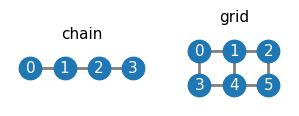

In [2]:
def device_hamiltonian(N, edges, Om, Dl, J):
    Hd = sp.csr_matrix((2 ** N, 2 ** N), dtype=complex)
    terms = 0
    for q in range(N):
        Hd = Hd + (Om / 2) * op_on_qubits({q: X}, N) + (Dl / 2) * op_on_qubits({q: Z}, N); terms += 2
    for (q, qq) in edges:
        Hd = Hd + (J / 2) * op_on_qubits({q: Z, qq: Z}, N); terms += 1
    return Hd.tocsr(), terms

N = 4
chain = [(q, q + 1) for q in range(N - 1)]
Hdev, n_terms = device_hamiltonian(N, chain, Om=1.0, Dl=0.3, J=1.0)
dense = (sum((0.5 * kron(*[X if i == q else I2 for i in range(N)]) + 0.15 * kron(*[Z if i == q else I2 for i in range(N)])) for q in range(N))
         + sum(0.5 * kron(*[Z if i in e else I2 for i in range(N)]) for e in chain))
assert np.allclose(Hdev.toarray(), dense, atol=TOL)                 # sparse and dense Kronecker products agree
assert n_terms == 2 * N + (N - 1)
assert Hdev.nnz == 2 ** N * (1 + N)                                 # one diagonal entry and N bit flips per row
print(f"chain of {N} qubits: {n_terms} Pauli strings, {Hdev.nnz} nonzero entries out of {4 ** N}")
NUMBERS["RegisterN"] = f"{N}"
NUMBERS["RegisterTerms"] = f"{n_terms}"
NUMBERS["RegisterNnz"] = f"{Hdev.nnz}"

fig, axes = plt.subplots(1, 2, figsize=(3.6, 1.5), gridspec_kw={"width_ratios": [1.3, 1]})   # final printed size, 11 pt text
for ax, (pos, edges, title) in zip(axes, [
        ({q: (q, 0) for q in range(4)}, chain, "chain"),
        ({q: (q % 3, -(q // 3)) for q in range(6)}, [(0, 1), (1, 2), (3, 4), (4, 5), (0, 3), (1, 4), (2, 5)], "grid")]):
    for a, b in edges:
        ax.plot(*zip(pos[a], pos[b]), color="0.5", lw=2, zorder=1)
    for q, (x, y) in pos.items():
        ax.scatter(x, y, s=260, color="C0", zorder=2)
        ax.text(x, y, str(q), color="white", ha="center", va="center", fontsize=11, zorder=3)
    xs = [p[0] for p in pos.values()]; ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 0.6, max(xs) + 0.6); ax.set_ylim(min(ys) - 0.6, max(ys) + 0.6)
    ax.set_title(title, fontsize=11); ax.set_aspect("equal"); ax.axis("off")
save(fig, "fig_lab068_register"); plt.show()

The chain has eight one-qubit terms, two per qubit, and three couplings. Each row of the matrix holds one diagonal entry from the $\hat Z$ terms. It also holds one entry for each of the four single bit flips produced by the $\hat X$ terms, so 80 of the 256 entries are nonzero. In the chain each qubit interacts only with its neighbours, while in the grid the inner qubits have three neighbours. A gate between two qubits that share no edge has to be routed through the graph.

## 2. Where qubit couplings come from

The coupling term of equation (1) is the effective result of a physical interaction, and each platform realises a different one. The table lists the mechanism, the resulting coupling written with Pauli operators, and the gate that the platform applies most directly, its native gate. The derivations are in the original papers cited below the table.

| platform | physical mechanism | effective coupling | native gate |
|---|---|---|---|
| neutral atoms in tweezers | van der Waals interaction $V$ of two atoms in Rydberg states | $V\,|rr\rangle\langle rr|$, which blocks double excitation | controlled-Z, by the Rydberg blockade gate |
| trapped ions | Coulomb repulsion, shared vibrational modes driven by two laser tones | $\hat X\hat X$ | $\hat R_{xx}(\theta)$ |
| superconducting circuits | capacitive or resonator coupling of two circuits | $\hat X\hat X+\hat Y\hat Y$ exchange, or $\hat Z\hat X$ under a cross-resonance drive | iSWAP or its inverse, or CNOT up to one-qubit gates |
| electron spins in quantum dots | exchange interaction $J(t)$ from the overlap of the electron orbitals | $J(t)\,\hat{\mathbf S}_0\cdot\hat{\mathbf S}_1$ | $\sqrt{\rm SWAP}$ |

The van der Waals interaction of Rydberg atoms, which falls as the inverse sixth power of their distance, is reviewed by M. Saffman, T. G. Walker and K. Mølmer, Rev. Mod. Phys. **82**, 2313 (2010), doi:10.1103/RevModPhys.82.2313. The Rydberg blockade gate was proposed by D. Jaksch, J. I. Cirac, P. Zoller, S. L. Rolston, R. Côté and M. D. Lukin, Phys. Rev. Lett. **85**, 2208 (2000), doi:10.1103/PhysRevLett.85.2208. The ion gate through shared vibrations is due to A. Sørensen and K. Mølmer, Phys. Rev. Lett. **82**, 1971 (1999), doi:10.1103/PhysRevLett.82.1971, and K. Mølmer and A. Sørensen, Phys. Rev. Lett. **82**, 1835 (1999), doi:10.1103/PhysRevLett.82.1835. The cross-resonance gate of superconducting qubits was analysed by C. Rigetti and M. Devoret, Phys. Rev. B **81**, 134507 (2010), doi:10.1103/PhysRevB.81.134507, and the exchange gate of quantum-dot spins was proposed by D. Loss and D. P. DiVincenzo, Phys. Rev. A **57**, 120 (1998), doi:10.1103/PhysRevA.57.120.

## 3. Interactions in Pauli language

Each physical interaction becomes a combination of Pauli strings once the projectors on the two levels are written with Pauli matrices. With $|0\rangle$ and $|1\rangle$ the two levels of a qubit,
$$|0\rangle\langle0|=\frac{\hat I+\hat Z}2,\qquad |1\rangle\langle1|=\frac{\hat I-\hat Z}2 . \tag{2}$$

When atoms are used to simulate an Ising model, each atom stores its qubit in the ground state $|g\rangle=|0\rangle$ and a Rydberg state $|r\rangle=|1\rangle$. Two atoms both in the Rydberg state repel each other with the energy $V$, which depends on their distance as $1/R^6$. The interaction acts only on the component $|rr\rangle=|11\rangle$, and equation (2) applied to both atoms gives
$$V\,|11\rangle\langle11|=V\,\frac{\hat I-\hat Z_0}2\,\frac{\hat I-\hat Z_1}2=\frac V4\big(\hat I-\hat Z_0-\hat Z_1+\hat Z_0\hat Z_1\big). \tag{3}$$
The Rydberg interaction is therefore an Ising coupling $\frac V4\hat Z_0\hat Z_1$ together with an energy shift $-\frac V4$ on each atom, which acts as a detuning, and a constant.

The exchange of one excitation between two circuits or two spins moves $|01\rangle$ to $|10\rangle$ and back. Its operator is a sum of two Pauli strings,
$$|01\rangle\langle10|+|10\rangle\langle01|=\frac12\big(\hat X_0\hat X_1+\hat Y_0\hat Y_1\big), \tag{4}$$
and the Heisenberg exchange of two spins, with the spin operators $\hat{\mathbf S}_q=\frac12(\hat X_q,\hat Y_q,\hat Z_q)$, is
$$\hat{\mathbf S}_0\cdot\hat{\mathbf S}_1=\frac14\big(\hat X_0\hat X_1+\hat Y_0\hat Y_1+\hat Z_0\hat Z_1\big). \tag{5}$$
We check the three identities numerically.

In [3]:
n1 = (I2 - Z) / 2                                                   # projector on |1>, equation (2)
assert np.allclose(kron(n1, n1), np.outer(ket("11"), ket("11")))
assert np.allclose(kron(n1, n1), (kron(I2, I2) - kron(Z, I2) - kron(I2, Z) + kron(Z, Z)) / 4)        # equation (3)
hop = np.outer(ket("01"), ket("10")); hop = hop + hop.conj().T
assert np.allclose(hop, (kron(X, X) + kron(Y, Y)) / 2)                                            # equation (4)
SdotS = sum(kron(s / 2, s / 2) for s in (X, Y, Z))
assert np.allclose(SdotS, (kron(X, X) + kron(Y, Y) + kron(Z, Z)) / 4)                             # equation (5)
print("equations (3), (4) and (5) hold")

equations (3), (4) and (5) hold


## 4. Gates generated by a coupling

A coupling switched on for a time $t$ applies the evolution operator $e^{-it\hat{\mathcal H}}$ to the register. For the Ising coupling $\hat{\mathcal H}=\frac J2\hat Z_0\hat Z_1$ this is the rotation $\hat R_{zz}(\theta)=e^{-i\theta\hat Z_0\hat Z_1/2}$ with the angle $\theta=Jt$. At $\theta=\pi/2$, followed by a rotation $\hat R_z(-\pi/2)=e^{i\pi\hat Z/4}$ on each qubit, it becomes the controlled-Z gate,
$$\widehat{\rm CZ}=e^{-i\pi/4}\,\big[\hat R_z(-\tfrac\pi2)\otimes\hat R_z(-\tfrac\pi2)\big]\,\hat R_{zz}(\tfrac\pi2)=|00\rangle\langle00|+|01\rangle\langle01|+|10\rangle\langle10|-|11\rangle\langle11| . \tag{6}$$
The derivation reads equation (3) backwards, since the gate $\widehat{\rm CZ}=e^{-i\pi|11\rangle\langle11|}$ is the evolution under the projector $|11\rangle\langle11|$, which equals a combination of $\hat Z_0\hat Z_1$, local $\hat Z$ terms and a constant. A Hadamard gate on the target on both sides turns $\widehat{\rm CZ}$ into the CNOT gate,
$$\widehat{\rm CNOT}=(\hat I\otimes\hat H)\,\widehat{\rm CZ}\,(\hat I\otimes\hat H), \tag{7}$$
because $\hat H\hat Z\hat H=\hat X$ turns the conditional sign flip into a conditional bit flip.

The other couplings of the table give their native gates in the same way. The exchange $\hat{\mathcal H}=\frac J2(\hat X_0\hat X_1+\hat Y_0\hat Y_1)$ at $Jt=\pi/2$ swaps $|01\rangle$ and $|10\rangle$ and multiplies them by $-i$, which is the inverse of the iSWAP gate. The opposite sign of $J$ gives iSWAP itself. The Heisenberg coupling $J\,\hat{\mathbf S}_0\cdot\hat{\mathbf S}_1$ at $Jt=\pi/2$ is a square root of SWAP, a gate that applied twice exchanges the two qubits. The ion coupling $\frac J2\hat X_0\hat X_1$ at $Jt=\pi/2$ gives $\hat R_{xx}(\pi/2)=e^{-i\pi\hat X_0\hat X_1/4}$, which prepares the Bell state
$$\hat R_{xx}(\tfrac\pi2)\,|00\rangle=\frac{|00\rangle-i|11\rangle}{\sqrt2}. \tag{8}$$
Each of these gates entangles, and together with arbitrary single-qubit rotations any one of them is universal, so every unitary operation on the register can be built from it. Different platforms therefore run the same circuits after compiling each gate into their native operations.

Before looking at the output below, write down the diagonal of $\hat R_{zz}(\pi/2)$ in the basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$. Then check that the local rotations of equation (6) leave only the sign on $|11\rangle$.

In [4]:
Rzz = lambda t: expm(-1j * t * kron(Z, Z) / 2)
Rz = lambda t: expm(-1j * t * Z / 2)
Rxx = lambda t: expm(-1j * t * kron(X, X) / 2)
print("diagonal of R_zz(pi/2):", np.round(np.diag(Rzz(np.pi / 2)), 4))
CZ = np.diag([1, 1, 1, -1]).astype(complex)
assert np.allclose(np.exp(-1j * np.pi / 4) * kron(Rz(-np.pi / 2), Rz(-np.pi / 2)) @ Rzz(np.pi / 2), CZ)   # equation (6)
assert np.allclose(expm(-1j * np.pi * np.outer(ket("11"), ket("11"))), CZ)
CNOT = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
assert np.allclose(kron(I2, H) @ CZ @ kron(I2, H), CNOT)                                           # equation (7)
iSWAP = np.array([[1, 0, 0, 0], [0, 0, 1j, 0], [0, 1j, 0, 0], [0, 0, 0, 1]])
U_ex = expm(-1j * (np.pi / 2) * (kron(X, X) + kron(Y, Y)) / 2)                                     # exchange, Jt = pi/2
assert np.allclose(U_ex, iSWAP.conj().T)
SWAP = (kron(I2, I2) + kron(X, X) + kron(Y, Y) + kron(Z, Z)) / 2
U_hb = expm(-1j * (np.pi / 2) * SdotS)                                                             # Heisenberg, Jt = pi/2
assert same_up_to_phase(U_hb @ U_hb, SWAP)
bell = Rxx(np.pi / 2) @ ket("00")
assert np.allclose(bell, (ket("00") - 1j * ket("11")) / np.sqrt(2))                                 # equation (8)
print("equations (6), (7) and (8), the exchange gate and the square root of SWAP hold")

diagonal of R_zz(pi/2): [0.7071-0.7071j 0.7071+0.7071j 0.7071+0.7071j 0.7071-0.7071j]
equations (6), (7) and (8), the exchange gate and the square root of SWAP hold


### Two-qubit angles set by interaction time

The angle of a two-qubit rotation is set like the angle of a laser pulse. A coupling $\frac{J(t)}2\hat Z_0\hat Z_1$ with a time-dependent strength commutes with itself at all times, so switching it on for the duration $T$ gives
$$\hat U=\hat R_{zz}(\theta),\qquad \theta=\int_0^TJ(t')\,dt' , \tag{9}$$
and $\theta=JT$ for a constant coupling. Any angle is reached by choosing the duration. A fixed gate such as CZ is one calibrated value, the duration $T=\pi/(2J)$ that gives $\theta=\pi/2$, followed by the local rotations of equation (6). A laboratory applies these rotations as phase shifts of later pulses.

Predict the duration that turns a constant coupling $J$ into the controlled-Z gate before running the code. The code checks that the angle grows linearly with the interaction time and that a smooth coupling pulse gives the rotation of its area. It also checks that CZ appears at the calibrated time.

In [5]:
ZZ = kron(Z, Z)
J_c = 1.3
times = np.linspace(0.0, 3.0, 7)
for t in times:
    assert np.allclose(expm(-1j * t * (J_c / 2) * ZZ), Rzz(J_c * t))       # theta = J t
T_c, J0 = 2.5, 1.0
J_of_t = lambda t: J0 * np.sin(np.pi * t / T_c) ** 2
n_steps = 2000; dt = T_c / n_steps
U_c = np.eye(4, dtype=complex)
for k in range(n_steps):
    U_c = expm(-1j * dt * 0.5 * J_of_t((k + 0.5) * dt) * ZZ) @ U_c
assert np.allclose(U_c, Rzz(J0 * T_c / 2), atol=1e-6)                     # equation (9)
t_cal = np.pi / (2 * J_c)
U_cal = np.exp(-1j * np.pi / 4) * kron(Rz(-np.pi / 2), Rz(-np.pi / 2)) @ expm(-1j * t_cal * (J_c / 2) * ZZ)
assert np.allclose(U_cal, CZ)
print(f"angle = J t at {len(times)} times; a sin^2 coupling pulse gives R_zz of its area; CZ at t = pi/(2J) = {t_cal:.3f} for J = {J_c}")


angle = J t at 7 times; a sin^2 coupling pulse gives R_zz of its area; CZ at t = pi/(2J) = 1.208 for J = 1.3


## 5. A blockade gate for two atoms

The Rydberg interaction of equation (3) is far stronger than any laser coupling when the atoms are a few micrometres apart. Jaksch and co-workers used this to propose a controlled-Z gate built directly from laser pulses. Each atom now stores its qubit in two long-lived ground levels $|0\rangle$ and $|1\rangle$ and has a third level, the Rydberg state $|r\rangle$. A laser couples only $|1\rangle$ to $|r\rangle$, with the Rabi frequency $\Omega$, and two atoms in $|r\rangle$ have the extra energy $V$. The Hamiltonian of the two atoms, each a three-level system, is
$$\hat{\mathcal H}=\frac{\Omega_0(t)}2\big(|1\rangle\langle r|+|r\rangle\langle1|\big)_0+\frac{\Omega_1(t)}2\big(|1\rangle\langle r|+|r\rangle\langle1|\big)_1+V\,|rr\rangle\langle rr| , \tag{10}$$
where the subscript names the atom on which the bracket acts and $\Omega_q(t)$ is $\Omega$ while the laser on atom $q$ is on and zero otherwise.

The gate consists of three resonant pulses. A $\pi$ pulse on the control atom 0 is followed by a $2\pi$ pulse on the target atom 1 and a second $\pi$ pulse on the control. A $2\pi$ pulse takes $|1\rangle$ to $|r\rangle$ and back and multiplies it by $-1$, while $|0\rangle$ is untouched. The four basis states therefore pick up the signs
- $|00\rangle$ is untouched,
- $|01\rangle$ and $|10\rangle$ each undergo one full $2\pi$ cycle and change sign,
- $|11\rangle$ sends the control to $|r\rangle$, and the strong interaction shifts the target transition out of resonance so that the target cannot be excited (the blockade). The control then returns with a sign change.

The result is $\mathrm{diag}(1,-1,-1,-1)=(\hat Z\otimes\hat Z)\,\widehat{\rm CZ}$, a controlled-Z gate up to a $\hat Z$ gate on each qubit. For a finite interaction the blockade is imperfect. To measure the quality we compare the $4\times4$ block $\hat M$ of the evolution on the qubit states with the ideal gate $\hat T$ through the average gate fidelity
$$F=\frac{|\mathrm{Tr}(\hat T^\dagger\hat M)|^2+\mathrm{Tr}(\hat M^\dagger\hat M)}{d(d+1)},\qquad d=4 , \tag{11}$$
where $\hat T=\mathrm{diag}(1,e^{i\alpha},e^{i\beta},-e^{i(\alpha+\beta)})$ is $\widehat{\rm CZ}$ followed by $\hat Z$ rotations, and the two angles $\alpha$, $\beta$ are optimised because such rotations are applied in software at no cost. For a finite $V$ the off-resonant target drive shifts the energy of $|r1\rangle$ by about $\Omega^2/(4V)$, a light shift. During the $2\pi$ pulse of duration $2\pi/\Omega$ the state $|11\rangle$ therefore acquires the extra phase $\pi\Omega/(2V)$. The error $1-F$ grows as the square of this phase, in proportion to $(\Omega/V)^2$. The doubly excited state $|rr\rangle$ is populated only transiently, with a probability of order $(\Omega/V)^2$, and the population left outside the qubit after the gate is much smaller.

gate on the qubit states for V/Omega = 10^6:
 [[ 1.+0.j  0.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j  0.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j -1.+0.j  0.+0.j]
 [ 0.+0.j  0.+0.j  0.+0.j -1.-0.j]]
error 1e-3 reached near V/Omega = 11.3
gate error at V/Omega = 10: 1.28e-03, at V/Omega = 40: 7.73e-05, log-log slope -2.02
extra phase of |11> matches pi*Omega/(2V) at V/Omega = 10, 20, 40
largest |rr> population on the |11> path for V/Omega = 20: 2.5e-03


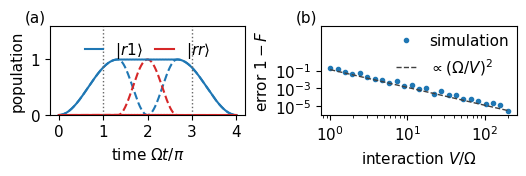

In [6]:
def P3(a, b):
    m = np.zeros((3, 3), dtype=complex); m[a, b] = 1
    return m
I3 = np.eye(3)
COMP = [0, 1, 3, 4]                       # |00>, |01>, |10>, |11> in the 9-dimensional space, index 3a + b

def blockade_hamiltonians(V, Om=1.0):
    drive = (Om / 2) * (P3(1, 2) + P3(2, 1))
    Hrr = V * np.kron(P3(2, 2), P3(2, 2))
    return np.kron(drive, I3) + Hrr, np.kron(I3, drive) + Hrr        # laser on the control, laser on the target

def blockade_gate(V, Om=1.0):
    Hc, Ht = blockade_hamiltonians(V, Om)
    U = expm(-1j * Hc * np.pi / Om) @ expm(-1j * Ht * 2 * np.pi / Om) @ expm(-1j * Hc * np.pi / Om)
    return U[np.ix_(COMP, COMP)]

def cz_fidelity(M):
    def neg(p):
        T = np.diag([1, np.exp(1j * p[0]), np.exp(1j * p[1]), -np.exp(1j * (p[0] + p[1]))])
        return -(abs(np.trace(T.conj().T @ M)) ** 2 + np.trace(M.conj().T @ M).real) / 20     # equation (11)
    starts = ([np.pi, np.pi], [0.0, 0.0], [np.angle(M[1, 1]), np.angle(M[2, 2])])
    return -min((minimize(neg, x0, method="Nelder-Mead", options={"xatol": 1e-10, "fatol": 1e-14}) for x0 in starts),
                key=lambda r: r.fun).fun

M_ideal = blockade_gate(1e6)
print("gate on the qubit states for V/Omega = 10^6:\n", np.round(M_ideal, 4))
assert np.allclose(M_ideal, np.diag([1, -1, -1, -1]), atol=1e-5)
assert np.allclose(np.diag([1, -1, -1, -1]), kron(Z, Z) @ CZ)          # (Z x Z) CZ
assert abs(cz_fidelity(M_ideal) - 1) < 1e-9

ratios = np.geomspace(1, 200, 25)
errors = np.array([1 - cz_fidelity(blockade_gate(V)) for V in ratios])
e10, e40 = (1 - cz_fidelity(blockade_gate(V)) for V in (10.0, 40.0))
slope = np.log(e40 / e10) / np.log(4)
assert abs(slope + 2) < 0.15 and e10 < 2e-3
V_target = 10 * np.sqrt(e10 / 1e-3)                                     # (Omega/V)^2 law through the point V/Omega = 10
assert 10 < V_target < 12.5
print(f"error 1e-3 reached near V/Omega = {V_target:.1f}")
NUMBERS["BlockVForMilli"] = f"{V_target:.0f}"
print(f"gate error at V/Omega = 10: {e10:.2e}, at V/Omega = 40: {e40:.2e}, log-log slope {slope:.2f}")
NUMBERS["BlockErrTen"] = sci(e10)
NUMBERS["BlockErrForty"] = sci(e40)
NUMBERS["BlockSlope"] = f"{slope:.1f}"

# the error comes from the extra phase pi*Omega/(2V) of |11>, set by the light shift Omega^2/(4V) of |r1>
for V in (10.0, 20.0, 40.0):
    a11 = blockade_gate(V)[3, 3]
    assert abs(np.angle(-a11) - np.pi / (2 * V)) < 0.02 * np.pi / (2 * V)
    assert 1 - abs(a11) ** 2 < 0.03 / V ** 2                              # leakage is much smaller than the phase error
print("extra phase of |11> matches pi*Omega/(2V) at V/Omega = 10, 20, 40")

# populations of the |11> path during the gate, with and without a strong interaction
def path_populations(V, steps=400, Om=1.0):
    Hc, Ht = blockade_hamiltonians(V, Om)
    psi = np.zeros(9, dtype=complex); psi[4] = 1
    rows = []
    for Hk, T in ((Hc, np.pi), (Ht, 2 * np.pi), (Hc, np.pi)):
        Uk = expm(-1j * Hk * T / Om / steps)
        for _ in range(steps):
            psi = Uk @ psi; rows.append(abs(psi) ** 2)
    return np.array(rows)

pops_strong = path_populations(20.0)
pops_none = path_populations(0.0)
rr = 8                                                                   # index of |rr>
NUMBERS["BlockRydMax"] = sci(pops_strong[:, rr].max())
print(f"largest |rr> population on the |11> path for V/Omega = 20: {pops_strong[:, rr].max():.1e}")
assert pops_strong[:, rr].max() < 0.02 and pops_none[:, rr].max() > 0.9

tt = np.linspace(0, 4 * np.pi, len(pops_strong))
with plt.rc_context({"font.size": 11, "axes.labelsize": 11, "legend.fontsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11}):
    fig, axes = plt.subplots(1, 2, figsize=(5.15, 1.65), constrained_layout=True)   # final printed size, 11 pt text
    r1 = 7                                                                   # index of |r1>, control excited
    for pops, ls, lab in ((pops_none, "--", r"$V=0$"), (pops_strong, "-", r"$V=20\,\Omega$")):
        axes[0].plot(tt / np.pi, pops[:, r1], color="C0", ls=ls)
        axes[0].plot(tt / np.pi, pops[:, rr], color="C3", ls=ls)
    axes[0].plot([], [], color="C0", label=r"$|r1\rangle$"); axes[0].plot([], [], color="C3", label=r"$|rr\rangle$")
    for xb in (1, 3):
        axes[0].axvline(xb, color="0.4", ls=":", lw=1)
    axes[0].set_xticks([0, 1, 2, 3, 4])
    axes[0].set_xlabel(r"time $\Omega t/\pi$"); axes[0].set_ylabel("population"); axes[0].set_ylim(0, 1.6)
    axes[0].legend(loc="upper center", ncol=2, frameon=False, handlelength=1.2, columnspacing=0.8)
    axes[1].loglog(ratios, errors, "o", ms=3, color="C0", label="simulation")
    axes[1].loglog(ratios, e10 * (10 / ratios) ** 2, color="0.25", ls="--", lw=1, label=r"$\propto(\Omega/V)^2$")
    axes[1].set_xlabel(r"interaction $V/\Omega$"); axes[1].set_ylabel(r"error $1-F$")
    axes[1].set_ylim(1e-6, 1e4); axes[1].set_yticks([1e-5, 1e-3, 1e-1]); axes[1].legend(frameon=False, loc="upper right", handlelength=1.4, borderaxespad=0.1)
    for ax, lbl in zip(axes, "ab"):
        ax.text(-0.02, 1.02, f"({lbl})", transform=ax.transAxes, ha="right", va="bottom")
    save(fig, "fig_lab068_blockade"); plt.show()


Panel (a) follows the state $|11\rangle$ through the three pulses, separated by the dotted lines at $\Omega t/\pi=1$ and $3$. The first pulse moves it to $|r1\rangle$, with the control in the Rydberg state. Without interaction (dashed) the target pulse then carries the population through $|rr\rangle$ and back. With $V=20\,\Omega$ (solid) the population stays in $|r1\rangle$ during the target pulse and $|rr\rangle$ remains almost empty, which is the blockade. Panel (b) shows the gate error after the free $\hat Z$ corrections. Below $V\approx2\Omega$ the error exceeds several per cent, because the target transition is barely shifted. For a strong interaction the error oscillates about a line of slope $-2$ on the logarithmic axes, as the extra phase $\pi\Omega/(2V)$ of $|11\rangle$ predicts. A gate error below $10^{-3}$ therefore requires an interaction about eleven times larger than the Rabi frequency. This requirement sets how close the atoms must be and which Rydberg level is used.

## 6. The Mølmer–Sørensen gate of two trapped ions

Two ions held in the same trap repel each other, so they cannot move independently. Their joint oscillation about the trap centre is a *motional mode*, a harmonic oscillator of frequency $\nu$ shared by both ions. Its quanta are *phonons*, created by $\hat a^\dagger$ and removed by $\hat a$, and a mode with $n$ phonons has the energy $n\nu$ above its ground state. A laser can change the qubit state and the number of phonons together. A laser tuned to the qubit frequency plus $\nu$ adds a phonon as it flips a qubit, and one tuned to the qubit frequency minus $\nu$ removes one. These two transitions are the blue and red *sidebands*. Their strength is reduced by the *Lamb–Dicke parameter* $\eta$, the ratio of the spread of the ion's ground-state motion to the wavelength of the light divided by $2\pi$. This parameter is small, typically $\eta\approx0.1$.

The gate of Sørensen and Mølmer drives both ions with two laser tones at once, detuned by $+(\nu-\delta)$ and $-(\nu-\delta)$ from the qubit frequency. The tones lie close to the two sidebands but off them by the small detuning $\delta$. To first order in $\eta$ and after the rotating-wave approximation, the two tones combine into a force on the motion whose sign depends on the qubits,
$$\hat{\mathcal H}(t)=g\,\hat S_x\big(\hat a\,e^{-i\delta t}+\hat a^\dagger e^{i\delta t}\big),\qquad \hat S_x=\tfrac12(\hat X_0+\hat X_1),\qquad g=\eta\Omega , \tag{12}$$
where $\Omega$ is the Rabi frequency of each tone. The collective spin $\hat S_x$ has the eigenvalues $m=1$, $0$ and $-1$, so the force pushes the motion in a direction set by the state of the two qubits.

For a fixed eigenvalue $m$ the force displaces the motional state by the amount $\alpha(t)\,m$ with
$$\alpha(t)=\frac g\delta\big(1-e^{i\delta t}\big) , \tag{13}$$
a circle in the plane of the motional amplitude that starts and ends at the origin. At the times $t=2\pi K/\delta$, with $K$ an integer, the motion returns to its initial state, whatever that state was, and the qubits are no longer entangled with the motion. The loop leaves behind a phase proportional to the enclosed area and to $m^2$. Since $\hat S_x^2=\frac12(\hat I+\hat X_0\hat X_1)$, this phase is an $\hat X\hat X$ coupling of the two qubits, the effective Hamiltonian $-\frac J2\hat X_0\hat X_1$ with $J=g^2/\delta$. For each $m$ the exact evolution is a displacement of the motion along the circle times the phase $e^{i\Phi(t)m^2}$, with $\Phi(t)=\frac{g^2}{\delta}\big(t-\frac{\sin\delta t}{\delta}\big)$, twice the area enclosed by the path. After $K$ loops it is
$$\hat U\Big(\frac{2\pi K}\delta\Big)=e^{\,i\Phi\hat S_x^2}=e^{i\Phi/2}\,\hat R_{xx}(-\Phi),\qquad \Phi=\frac{2\pi K g^2}{\delta^2} . \tag{14}$$
For $\delta>0$ the gate rotates by $-\Phi$, the opposite sense to the rotation $\hat R_{xx}(+\pi/2)$ that creates a Bell state in Lab 065, and the opposite sign of $\delta$ reverses the rotation. One loop with $\delta=2g$ gives $\Phi=\pi/2$ and the maximally entangling gate $\hat R_{xx}(-\pi/2)$, which takes $|00\rangle$ to $(|00\rangle+i|11\rangle)/\sqrt2$. The angle is set by the drive strength, the detuning and the number of loops, so a continuous $\hat R_{xx}(\theta)$ follows from choosing $\delta=g\sqrt{2\pi K/|\theta|}$.

The code simulates two qubits and a motional mode truncated at 24 phonons. It follows the motional amplitude, the purity of the qubit state and the Bell-state fidelity. It then repeats the gate for ions that start in thermal motion with mean phonon numbers $\bar n=0.5$, $1$ and $2$. Before running it, predict the fidelity for the hottest ions from equation (14).

mean phonon number 0: Bell-state fidelity 1.000000
mean phonon number 0.5: Bell-state fidelity 1.000000
mean phonon number 1: Bell-state fidelity 0.999999
mean phonon number 2: Bell-state fidelity 0.999944
the loop closes at t = 2 pi / delta, the qubits end in a pure Bell state for every motional state


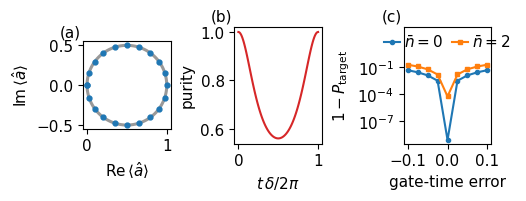

In [7]:
# Mølmer–Sørensen gate: two qubits and one motional mode, Hamiltonian (12)
nph = 24                                                  # phonon cutoff
a_ph = np.diag(np.sqrt(np.arange(1, nph)), 1).astype(complex)
Iph = np.eye(nph)
Sx2q = (kron(X, I2) + kron(I2, X)) / 2
SX, A_full = np.kron(Sx2q, Iph), np.kron(np.eye(4), a_ph)
g_ms = 1.0                                                # g = eta * Omega, the unit of frequency

def ms_propagator(delta, T, steps=600):
    # time-ordered product of short steps with the midpoint Hamiltonian
    U, dt = np.eye(4 * nph, dtype=complex), T / steps
    for k in range(steps):
        t = (k + 0.5) * dt
        Hm = g_ms * SX @ (A_full * np.exp(-1j * delta * t) + A_full.conj().T * np.exp(1j * delta * t))
        w, V = np.linalg.eigh(Hm)
        U = (V * np.exp(-1j * w * dt)) @ V.conj().T @ U
    return U

def spin_state(psi):
    M = psi.reshape(4, nph)
    return M @ M.conj().T                                  # reduced density matrix of the two qubits

delta_ms = 2 * g_ms; T_ms = 2 * np.pi / delta_ms           # one loop, Phi = pi/2
Phi = 2 * np.pi * g_ms ** 2 / delta_ms ** 2
bell_ms = expm(1j * Phi / 2 * kron(X, X)) @ ket("00")      # R_xx(-Phi)|00>, equation (14)
assert np.allclose(bell_ms, (ket("00") + 1j * ket("11")) / np.sqrt(2))

# motional amplitude <a>(t) for the qubits in |++> (m = 1) and spin purity for |00>
plusplus = kron(H, H) @ ket("00")
n_t = 120; ts = np.linspace(0, T_ms, n_t + 1); dt_s = T_ms / n_t
psi_pp = np.kron(plusplus, Iph[0]).astype(complex); psi_00 = np.kron(ket("00"), Iph[0]).astype(complex)
alpha_num, purity = [0j], [1.0]
for k in range(n_t):
    t0 = ts[k]
    for sub in range(5):                                   # five midpoint substeps per plotted interval
        t = t0 + (sub + 0.5) * dt_s / 5
        Hm = g_ms * SX @ (A_full * np.exp(-1j * delta_ms * t) + A_full.conj().T * np.exp(1j * delta_ms * t))
        w, V = np.linalg.eigh(Hm); Us = (V * np.exp(-1j * w * dt_s / 5)) @ V.conj().T
        psi_pp, psi_00 = Us @ psi_pp, Us @ psi_00
    alpha_num.append(np.vdot(psi_pp, A_full @ psi_pp))
    rho_s = spin_state(psi_00); purity.append(np.real(np.trace(rho_s @ rho_s)))
alpha_num = np.array(alpha_num); alpha_an = g_ms / delta_ms * (1 - np.exp(1j * delta_ms * ts))
assert np.max(np.abs(alpha_num - alpha_an)) < 1e-3                                   # equation (13), m = 1
assert abs(alpha_num[-1]) < 1e-3 and abs(purity[-1] - 1) < 1e-6                      # loop closed, qubits free of the motion

# fidelity of the Bell state for thermal motion
U_ms = ms_propagator(delta_ms, T_ms)
def bell_fidelity(nbar, U):
    p = np.ones(1) if nbar == 0 else (nbar / (nbar + 1)) ** np.arange(16) / (nbar + 1)
    p = p / p.sum(); rho = np.zeros((4, 4), dtype=complex)
    for n, pn in enumerate(p):
        rho += pn * spin_state(U @ np.kron(ket("00"), Iph[n]))
    return np.real(np.vdot(bell_ms, rho @ bell_ms))
nbars = [0, 0.5, 1, 2]
fids = [bell_fidelity(nb_, U_ms) for nb_ in nbars]
for nb_, F in zip(nbars, fids):
    print(f"mean phonon number {nb_}: Bell-state fidelity {F:.6f}")
assert min(fids) > 1 - 1e-4
# the gate time must close the loop: error for a mismatched time
eps = np.linspace(-0.1, 0.1, 9)
err_cold = [1 - bell_fidelity(0, ms_propagator(delta_ms, T_ms * (1 + e), 300)) for e in eps]
err_hot = [1 - bell_fidelity(2, ms_propagator(delta_ms, T_ms * (1 + e), 300)) for e in eps]
assert err_hot[0] > err_cold[0] > 1e-3
NUMBERS["MsFidHot"] = f"{fids[-1]:.4f}"
NUMBERS["MsErrColdTen"] = f"{err_cold[0]:.3f}"
NUMBERS["MsErrHotTen"] = f"{err_hot[0]:.3f}"

with plt.rc_context({"font.size": 11, "axes.labelsize": 11, "legend.fontsize": 11, "xtick.labelsize": 11, "ytick.labelsize": 11}):
    fig, axes = plt.subplots(1, 3, figsize=(5.15, 1.9), constrained_layout=True)   # final printed size, 11 pt text
    axes[0].plot(alpha_an.real, alpha_an.imag, color="0.6", lw=2.2, zorder=1)
    axes[0].plot(alpha_num.real[::6], alpha_num.imag[::6], "o", ms=3.5, color="#1f77b4", zorder=2)
    axes[0].set_aspect("equal"); axes[0].set_xlabel(r"Re$\,\langle\hat a\rangle$"); axes[0].set_ylabel(r"Im$\,\langle\hat a\rangle$")
    axes[1].plot(ts / T_ms, purity, color="#d62728")
    axes[1].set_xlabel(r"$t\,\delta/2\pi$"); axes[1].set_ylabel("purity")
    axes[2].plot(eps, err_cold, "o-", ms=3, label=r"$\bar n=0$"); axes[2].plot(eps, err_hot, "s-", ms=3, label=r"$\bar n=2$")
    axes[2].set_yscale("log"); axes[2].set_xlabel("gate-time error"); axes[2].set_ylabel(r"$1-P_{\rm target}$")
    axes[2].set_ylim(top=3e3); axes[2].set_yticks([1e-7, 1e-4, 1e-1])
    axes[2].legend(frameon=False, handlelength=1.0, ncol=2, loc="upper center", columnspacing=0.6, handletextpad=0.3, borderaxespad=0.1)
    for ax, lbl in zip(axes, "abc"):
        ax.text(-0.02, 1.02, f"({lbl})", transform=ax.transAxes, ha="right", va="bottom")
    save(fig, "fig_lab068_ms_gate"); plt.show()
print("the loop closes at t = 2 pi / delta, the qubits end in a pure Bell state for every motional state")

Panel (a) shows the mean motional amplitude (dots) against the analytic circle (grey line) for the qubits in $|{+}{+}\rangle$, the eigenstate of $\hat S_x$ with $m=1$. It runs around the circle of equation (13) and returns to the origin at the gate time. Panel (b) starts from $|00\rangle$, a superposition of the three eigenvalues of $\hat S_x$. During the loop the qubits are entangled with the motion and their purity drops. At the gate time the purity returns to one and the qubits hold the entangled state $(|00\rangle+i|11\rangle)/\sqrt2$, a Bell state. The probability of finding this state stays above $0.9999$ for thermal motion up to $\bar n=2$, because every motional state is carried around the same closed loop. The small remaining loss comes from the truncation of the motional mode and the finite time step. In this model, closing the motional loop produces the same qubit gate for all initial motional states considered here. Panel (c) shows the error $1-P_{\rm target}$, one minus the probability of the target Bell state, and that the gate time must close the loop. A time wrong by ten per cent leaves the qubits entangled with the motion, and the error is larger for hotter ions, whose motion carries more phonons.

## 7. Gates between distant qubits

On a chain only neighbours interact, yet algorithms need gates between any two qubits. A SWAP gate between neighbours exchanges their states, so a chain of SWAP gates moves the state of a distant qubit next to its partner. For qubits 0 and 3 of a four-qubit chain we swap qubits 3 and 2 and then 2 and 1. We apply $\widehat{\rm CZ}$ to qubits 0 and 1 and undo the two swaps,
$$\widehat{\rm CZ}_{0,3}=\widehat{\rm SWAP}_{2,3}\,\widehat{\rm SWAP}_{1,2}\,\widehat{\rm CZ}_{0,1}\,\widehat{\rm SWAP}_{1,2}\,\widehat{\rm SWAP}_{2,3} , \tag{15}$$
read from right to left. Two qubits at distance $d$ on the chain need $2(d-1)$ SWAP gates, and each SWAP costs three CNOT gates. Connectivity therefore multiplies the cost of a circuit. Richer connectivity graphs reduce this overhead. So do qubits that can be moved, such as atoms in tweezers or ions in segmented traps, whose electrodes are divided into zones that shuttle ions between them.

In [8]:
def gate_on_pair(G, q, N=4):
    # two-qubit gate G on the neighbouring qubits q, q+1 of an N-qubit chain (dense, small N)
    return kron(np.eye(2 ** q), G, np.eye(2 ** (N - q - 2)))

CZ03 = np.diag([(-1) ** (((b >> 3) & 1) * (b & 1)) for b in range(16)]).astype(complex)
sequence = gate_on_pair(SWAP, 2) @ gate_on_pair(SWAP, 1) @ gate_on_pair(CZ, 0) @ gate_on_pair(SWAP, 1) @ gate_on_pair(SWAP, 2)
assert np.allclose(sequence, CZ03)                                                  # equation (15)
assert np.allclose(SWAP, CNOT @ (kron(H, H) @ CNOT @ kron(H, H)) @ CNOT)            # three CNOTs, the middle one reversed
d = 3
n_swaps = 2 * (d - 1)
print(f"CZ between qubits 0 and 3: {n_swaps} SWAP gates = {3 * n_swaps} CNOT gates, plus one CZ")
NUMBERS["SwapCount"] = f"{n_swaps}"
NUMBERS["SwapCnots"] = f"{3 * n_swaps}"

CZ between qubits 0 and 3: 4 SWAP gates = 12 CNOT gates, plus one CZ


## 8. A gate library on a chain of $L$ spins

The gates above act on two qubits, and a register has $L$ of them. Every gate on a chain is the exponential of its generator, embedded with identities on the other spins. With the chain operators $\hat X_j$, $\hat Y_j$, $\hat Z_j$ built as sparse Kronecker products, the library reads
$$\hat R^\alpha_j(\theta)=e^{-i\theta\hat\sigma^\alpha_j/2},\qquad \hat P_j(\theta)=e^{i\theta/2}\hat R^z_j(\theta),\qquad \hat R^{xx}_{ij}(\theta)=e^{-i\theta\hat X_i\hat X_j/2}, \tag{16}$$
$$\widehat{\rm CNOT}_{ij}=e^{\,i\pi(\hat I-\hat Z_i)(\hat I-\hat X_j)/4},\qquad \widehat{\rm SWAP}_{ij}=\tfrac12\big(\hat I+\hat X_i\hat X_j+\hat Y_i\hat Y_j+\hat Z_i\hat Z_j\big),\qquad \widehat{\rm Toffoli}_{ijk}=e^{-i\pi(\hat I-\hat Z_i)(\hat I-\hat Z_j)(\hat I-\hat X_k)/8} , \tag{17}$$
where in CNOT the qubit $i$ is the control and $j$ the target, and in Toffoli $i$ and $j$ are the controls. Each generator has one of the physical origins met above. The one-qubit rotations are laser pulses, and $\hat X_i\hat X_j$ is the Mølmer–Sørensen coupling of Section 6. The product $\hat Z_i\hat X_j$ inside the CNOT generator is the cross-resonance coupling of superconducting circuits listed in Section 2, and SWAP is the Heisenberg exchange of equation (5). The code checks every gate against its projector or Kronecker form and on basis states, with control and target in the stated order.

The same chain operators build Hamiltonians. The Heisenberg chain
$$\hat{\mathcal H}=-\frac12\sum_{j=0}^{L-2}\big(J_x\hat X_j\hat X_{j+1}+J_y\hat Y_j\hat Y_{j+1}+J_z\hat Z_j\hat Z_{j+1}\big)+h\sum_{j=0}^{L-1}\hat Z_j \tag{18}$$
with $J_x=J_y=J_z=-1$ is antiferromagnetic. For $L=5$ and $h=0.1$ the code finds its ground state with a sparse eigensolver and lists the bit strings that carry most of the probability $|\psi_k|^2$.

In [9]:
# gate library on a chain of L spins, equations (16) and (17)
from scipy.sparse.linalg import eigsh
L = 5
def chain(P, j):  return op_on_qubits({j: P}, L)
def Rgate(alpha, theta, j):  return expm(-1j * theta / 2 * chain({"x": X, "y": Y, "z": Z}[alpha], j).toarray())
def Pgate(theta, j):  return np.exp(1j * theta / 2) * Rgate("z", theta, j)
def RXX(i, j, theta):  return expm(-1j * theta / 2 * (chain(X, i) @ chain(X, j)).toarray())
IL = np.eye(2 ** L)
def CNOTg(i, j):  return expm(1j * np.pi / 4 * ((IL - chain(Z, i)) @ (IL - chain(X, j))))     # i control, j target
def SWAPg(i, j):  return 0.5 * (IL + (chain(X, i) @ chain(X, j) + chain(Y, i) @ chain(Y, j) + chain(Z, i) @ chain(Z, j)).toarray())
def TOFFg(i, j, k):  return expm(-1j * np.pi / 8 * ((IL - chain(Z, i)) @ (IL - chain(Z, j)) @ (IL - chain(X, k))))

P0q, P1q = np.diag([1, 0]).astype(complex), np.diag([0, 1]).astype(complex)
def bits_of(b):  return [(b >> (L - 1 - q)) & 1 for q in range(L)]
def index_of(bits):  return int("".join(map(str, bits)), 2)
for (i, j) in [(0, 3), (3, 0), (1, 2)]:
    proj = (op_on_qubits({i: P0q}, L) + op_on_qubits({i: P1q, j: X}, L)).toarray()
    assert np.allclose(CNOTg(i, j), proj, atol=1e-10)                       # projector form, i control
    for b in range(2 ** L):
        bb = bits_of(b); out = bb.copy(); out[j] ^= bb[i]
        assert abs(CNOTg(i, j)[index_of(out), b] - 1) < 1e-10                # flips j when i is 1
        sw = bb.copy(); sw[i], sw[j] = bb[j], bb[i]
        assert abs(SWAPg(i, j)[index_of(sw), b] - 1) < 1e-10
for b in range(2 ** L):
    bb = bits_of(b); out = bb.copy(); out[4] ^= bb[0] & bb[2]
    assert abs(TOFFg(0, 2, 4)[index_of(out), b] - 1) < 1e-10                 # flips 4 when 0 and 2 are 1
th = 0.83
assert np.allclose(Rgate("x", th, 2), kron(np.eye(4), expm(-1j * th / 2 * X), np.eye(4)))
assert np.allclose(Pgate(th, 1), kron(I2, np.diag([1, np.exp(1j * th)]), np.eye(8)))
assert np.allclose(RXX(0, 4, th), np.cos(th / 2) * IL - 1j * np.sin(th / 2) * (chain(X, 0) @ chain(X, 4)).toarray())
print("every gate of the library equals its projector or Kronecker form; CNOT_ij has control i and target j")

def heisenberg_chain(Jx, Jy, Jz, h):
    Hc = sp.csr_matrix((2 ** L, 2 ** L), dtype=complex)
    for j in range(L - 1):
        Hc = Hc - 0.5 * (Jx * chain(X, j) @ chain(X, j + 1) + Jy * chain(Y, j) @ chain(Y, j + 1) + Jz * chain(Z, j) @ chain(Z, j + 1))
    for j in range(L):
        Hc = Hc + h * chain(Z, j)
    return Hc
Hc = heisenberg_chain(-1, -1, -1, 0.1)
E0, psi0 = eigsh(Hc, k=1, which="SA")
assert abs(E0[0] - np.linalg.eigvalsh(Hc.toarray())[0]) < 1e-9
prob = np.abs(psi0[:, 0]) ** 2
print(f"ground-state energy of the Heisenberg chain, L = {L}: {E0[0]:.4f}")
for k in np.argsort(prob)[::-1][:6]:
    print(f"  |{format(k, f'0{L}b')}>  |psi_k|^2 = {prob[k]:.4f}")
ones = np.array([bin(k).count("1") for k in range(2 ** L)])
assert abs(prob[ones == 3].sum() - 1) < 1e-9 and int(np.argmax(prob)) == int("10101", 2)   # one magnetisation sector
NUMBERS["ChainEnergy"] = f"{E0[0]:.4f}"
NUMBERS["ChainTopWeight"] = f"{prob.max():.2f}"

every gate of the library equals its projector or Kronecker form; CNOT_ij has control i and target j
ground-state energy of the Heisenberg chain, L = 5: -3.9558
  |10101>  |psi_k|^2 = 0.4428
  |10110>  |psi_k|^2 = 0.1478
  |01101>  |psi_k|^2 = 0.1478
  |11001>  |psi_k|^2 = 0.0543
  |11010>  |psi_k|^2 = 0.0543
  |10011>  |psi_k|^2 = 0.0543


The largest weight, about 0.44, sits on the alternating string $10101$, in which neighbouring spins are opposite. All other weight lies on strings with three spins in $|1\rangle$, the sector favoured by the small field. The weight stays in this sector because the exchange terms move flipped spins along the chain but keep their number fixed.

## 9. Exercises

1. Write the Hamiltonian $J\,\hat{\mathbf S}_0\cdot\hat{\mathbf S}_1$ of equation (5) in the basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$ and find its eigenvalues. Identify the singlet and the three triplet states.
2. Show from equation (3) that a Rydberg interaction switched on for the time $t=\pi/V$ applies $\widehat{\rm CZ}$ up to single-qubit $\hat Z$ rotations, and find the angles of these rotations.
3. Replace the $2\pi$ pulse on the target in the simulation of Section 5 by a pulse of area $1.9\pi$ and measure the gate error at $V=50\,\Omega$. Explain the result.
4. Add a coupling between qubits 0 and 3 to the chain of Section 1 to form a ring. Count the Pauli strings and the nonzero entries of the new Hamiltonian.
5. Find the number of SWAP gates needed for a gate between opposite corners of a three-by-three grid with nearest-neighbour couplings.

## 10. Summary

A register of qubits is a set of addressable two-level systems on a connectivity graph. Its Hamiltonian consists of one-qubit drive terms and two-qubit couplings, all of them Pauli strings. Each platform obtains its coupling from different physics. Neutral atoms use the Rydberg interaction, ions their shared vibrations, superconducting circuits capacitive and resonator couplings, and quantum-dot spins the exchange interaction. Written with the projectors $(\hat I\pm\hat Z)/2$, these interactions become Ising, exchange or Heisenberg couplings. A coupling switched on for a fixed time is a two-qubit gate. With single-qubit rotations the Ising coupling compiles into the controlled-Z and CNOT gates, and the exchange and Heisenberg couplings give the inverse iSWAP and square-root-of-SWAP gates. Any of these gates together with single-qubit rotations is universal. The simulated Rydberg blockade gate reaches the controlled-Z gate up to local $\hat Z$ rotations, with an error that falls as $(\Omega/V)^2$. In trapped ions a two-tone drive pushes the shared motion around a closed loop in phase space. The loop leaves the $\hat X\hat X$ rotation of the Mølmer–Sørensen gate and works for thermal motion. Gates between distant qubits of a chain are routed with SWAP gates, whose number grows with the distance. Every gate on a chain of $L$ spins is the exponential of a generator embedded with identities, and the same chain operators build the Heisenberg Hamiltonian.